# The cell boundary mask as a third input channel

SubCellSpace reads two input channels: the transcript image and DAPI. This notebook compares
it with the same CVAE given the segmented cell mask as a third channel. Both models were
trained with the same script, seed, held-out cell split and hyperparameters, differing only
in the number of input channels.

Trained identically, at 100 and at 300 epochs, the two models recover subcellular patterns
equally well on held-out simulations (§1: pattern-probe κ 0.747 against 0.750 at 300
epochs). On real data neither is consistently better at calling localised genes: on the
Xenium HEK293T data the 2-channel model calls more localised genes (139 against 132 of 224)
and the cell-mask model fewer control genes (5 against 7 of 26); on the MERFISH small
intestine both make one false call (§2). The extra channel therefore brings no measurable
gain. Supp. Fig. 17 shows both results.

The cell boundary is not absent from the 2-channel input: each observation is a
**per-cell crop**, so the cell's extent defines the image frame itself, and DAPI marks the
nucleus. An explicit mask adds a signal that is the same for every RNA in a given cell.

In [1]:
import paths
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt

DATA = paths.data("cell_mask")
FIG  = paths.figures("cell_mask")

ARMS  = {"run2ch_e100": "2-channel, 100 ep", "run2ch_e300": "2-channel, 300 ep",
         "run3ch_e100": "+ cell mask, 100 ep", "run3ch_e300": "+ cell mask, 300 ep"}
TWO, THREE = "#2a78d6", "#eb6834"
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2df"
mpl.rcParams.update({"figure.facecolor":SURFACE,"axes.facecolor":SURFACE,
    "savefig.facecolor":SURFACE,"text.color":INK,"axes.labelcolor":INK_MUTED,
    "xtick.color":INK_MUTED,"ytick.color":INK_MUTED,"axes.edgecolor":GRID,"font.size":9,
    "axes.titlesize":10,"figure.dpi":120,"axes.spines.top":False,
    "axes.spines.right":False,"legend.frameon":False})
def tidy(ax, axis="y"):
    ax.grid(True, axis=axis, color=GRID, lw=0.6, zorder=0); ax.set_axisbelow(True)

# produced by scripts/cell_mask/encode_and_score.py and scripts/cell_mask/score_matched_detection.py
sweep = pd.read_csv(DATA / "epoch_sweep_raw.csv")
det   = pd.read_csv(DATA / "matched_detection_raw.csv")

## 1. Trained the same way, the two models are indistinguishable on simulated data

Both models were trained from scratch by one script on one day, with the same seed and the
same held-out cell split, differing only in the number of input channels. A random-forest
probe reads pattern identity from the 15-dimensional latent of the held-out simulated
observations (5 cross-validation folds × 3 repeats).

In [2]:
def summary(metric_rows):
    return (metric_rows.groupby("method")["value"].mean()
            .reindex(list(ARMS)).rename(index=ARMS))

kappa = summary(sweep[(sweep.benchmark == "pattern_probe") & (sweep.metric == "kappa")
                      & sweep.class_label.isna()])
tbl = pd.DataFrame({"pattern probe kappa": kappa})
published = sweep[(sweep.method == "shipped_2ch") & (sweep.benchmark == "pattern_probe")
                & (sweep.metric == "kappa") & sweep.class_label.isna()]["value"].mean()
print(f"(the published checkpoint, re-encoded through this same path, scores "
      f"{published:.4f} on pattern kappa — a reproduction check on the pipeline)\n")
tbl

(the published checkpoint, re-encoded through this same path, scores 0.7758 on pattern kappa — a reproduction check on the pipeline)



,pattern probe kappa
method,
"2-channel, 100 ep",0.735233
"2-channel, 300 ep",0.747378
"+ cell mask, 100 ep",0.728564
"+ cell mask, 300 ep",0.749594


The two are level at matched training length: **0.747 against 0.750** at 300 epochs and
0.735 against 0.729 at 100, a difference far smaller than the gap between either and the
published checkpoint (0.776) trained from the same code on the same data. Training three
times as long does not separate them.

## 2. The call on real data

Gene-level detection, scored with a classifier refitted to each model's own latent, one
shared shuffled null per dataset and the published distance thresholds (0.06 Xenium,
0.03 small intestine). Both models at 300 epochs. Only genes with a ground-truth label
are scored: 224 localised and 26 control genes on the Xenium data, 17 and 13 on the
small intestine.

In [3]:
calls = (det[(det.benchmark == "detection_at_threshold") & det.metric.isin(["tp", "fp", "tn", "fn"])]
         .groupby(["dataset", "method", "metric"])["value"].mean().unstack("metric"))
MODELS = {"subcellspace_2ch_e300": ("2-channel, 300 ep", TWO),
          "subcellspace_3ch_e300": ("+ cell mask, 300 ep", THREE)}
DATASETS = {"apex_hek": "Xenium HEK293T", "ileum": "MERFISH small intestine"}
rows = []
for ds, dname in DATASETS.items():
    for m, (mname, _) in MODELS.items():
        r = calls.loc[(ds, m)]
        rows.append({"dataset": dname, "model": mname,
                     "localised genes called": f"{int(r.tp)}/{int(r.tp + r.fn)}",
                     "control genes called": f"{int(r.fp)}/{int(r.fp + r.tn)}"})
pd.DataFrame(rows).set_index(["dataset", "model"])

localised genes called  \
dataset                 model                                        
Xenium HEK293T          2-channel, 300 ep                  139/224   
                        + cell mask, 300 ep                132/224   
MERFISH small intestine 2-channel, 300 ep                    11/17   
                        + cell mask, 300 ep                  12/17   

                                            control genes called  
dataset                 model                                     
Xenium HEK293T          2-channel, 300 ep                   7/26  
                        + cell mask, 300 ep                 5/26  
MERFISH small intestine 2-channel, 300 ep                   1/13  
                        + cell mask, 300 ep                 1/13

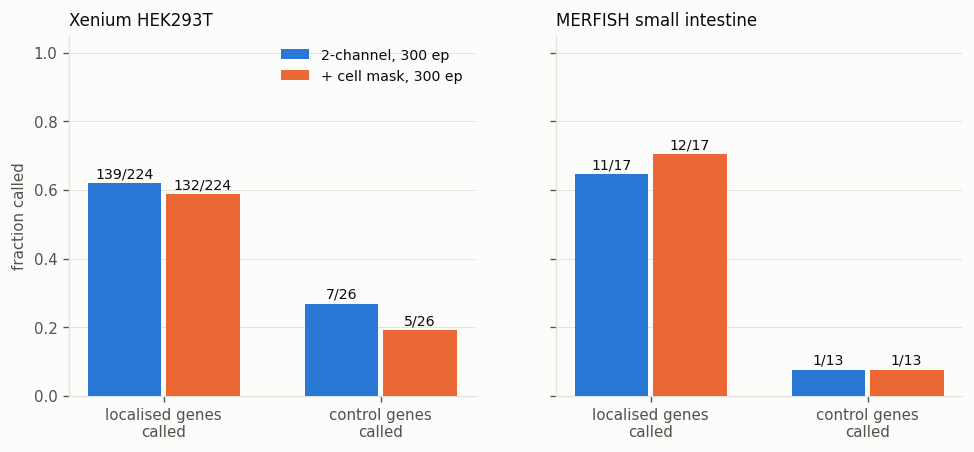

In [4]:
def fig_detection():
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9), sharey=True)
    for ax, (ds, dname) in zip(axes, DATASETS.items()):
        for i, (m, (mname, col)) in enumerate(MODELS.items()):
            r = calls.loc[(ds, m)]
            npos, nneg = int(r.tp + r.fn), int(r.fp + r.tn)
            xs = np.arange(2) + (i - 0.5) * 0.36
            ax.bar(xs, [r.tp / npos, r.fp / nneg], 0.34, color=col, zorder=3, label=mname)
            for x, n, tot in zip(xs, (r.tp, r.fp), (npos, nneg)):
                ax.annotate(f"{int(n)}/{tot}", (x, n / tot), xytext=(0, 3),
                            textcoords="offset points", ha="center", fontsize=8.5, color=INK)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["localised genes\ncalled", "control genes\ncalled"])
        ax.set_ylim(0, 1.05); ax.set_title(dname, loc="left", color=INK); tidy(ax)
    axes[0].set_ylabel("fraction called")
    axes[0].legend(fontsize=8.5, loc="upper right")
    fig.savefig(FIG/"detection_calls.png", bbox_inches="tight", dpi=170)

fig_detection(); plt.show()

Neither model is consistently better. On the Xenium data the 2-channel model calls 139
of the 224 localised genes against 132, while the cell-mask model makes 5 false calls
against 7. On the small intestine the cell-mask model finds one more localised gene and
both make one false call; with 30 genes that is a single-gene difference. The extra
channel brings no improvement on either dataset.

## Summary

Adding the cell mask as a third input channel does not improve SubCellSpace. Matched
training leaves the two models level at recovering simulated patterns, at 100 and at 300
epochs, and on real data neither model is consistently better at calling localised genes.
The per-cell crop already sets the cell's extent and DAPI marks the nucleus; supplying the
boundary again as a dedicated channel adds a signal that is constant across every RNA in a
cell, and brings no measurable gain.

## Supp. Fig. 17

The supplementary page, drawn from the same two tables.

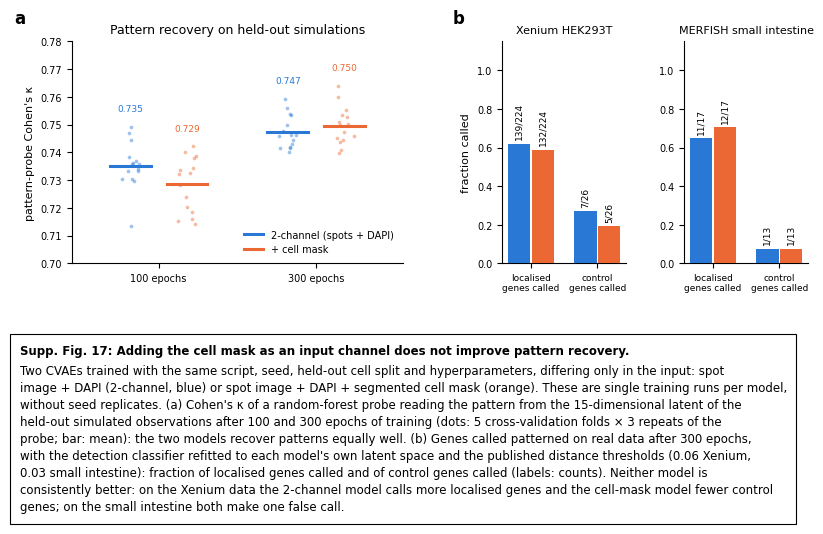

In [5]:
from matplotlib.lines import Line2D
from supp_style import new_page, panel_letter, caption_box, save_page, COL

MODELS_PAGE = [("2ch", "2-channel (spots + DAPI)", TWO), ("3ch", "+ cell mask", THREE)]

kap = sweep[(sweep.benchmark == "pattern_probe") & (sweep.metric == "kappa") & sweep.class_label.isna()]
assert (kap.groupby("method").size() == 15).all()
assert calls.loc[("apex_hek", "subcellspace_2ch_e300"), ["tp", "fp"]].tolist() == [139, 7]
assert calls.loc[("apex_hek", "subcellspace_3ch_e300"), ["tp", "fp"]].tolist() == [132, 5]
assert calls.loc[("ileum", "subcellspace_2ch_e300"), ["tp", "fp"]].tolist() == [11, 1]
assert calls.loc[("ileum", "subcellspace_3ch_e300"), ["tp", "fp"]].tolist() == [12, 1]
km = kap.groupby("method").value.mean()
for m, k_exp in [("run2ch_e100", .735), ("run2ch_e300", .747), ("run3ch_e100", .729), ("run3ch_e300", .750)]:
    assert round(km[m], 3) == k_exp, m

fig = new_page()

# ---------- a: simulated data ----------
def dots(ax, df, ylab, title, fmt):
    rng = np.random.RandomState(0)
    for gi, ep in enumerate((100, 300)):
        for mi, (key, lab, col) in enumerate(MODELS_PAGE):
            v = df[df.method == f"run{key}_e{ep}"].value.values
            x = gi + (mi - 0.5) * 0.36
            ax.scatter(x + rng.uniform(-0.06, 0.06, len(v)), v, s=7, color=col, alpha=0.45,
                       linewidths=0, zorder=3)
            ax.plot([x - 0.13, x + 0.13], [v.mean()] * 2, color=col, lw=2.2, zorder=4)
            ax.text(x, v.max() + 0.06 * np.ptp(ax.get_ylim()), fmt.format(v.mean()), ha="center",
                    va="bottom", fontsize=6.5, color=col)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["100 epochs", "300 epochs"])
    ax.set_xlim(-0.55, 1.55); ax.set_ylabel(ylab); ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)

ax_a1 = fig.add_axes([0.10, 0.76, 0.40, 0.19]); ax_a1.set_ylim(0.70, 0.78)
dots(ax_a1, kap, "pattern-probe Cohen's κ", "Pattern recovery on held-out simulations", "{:.3f}")
panel_letter(fig, ax_a1, "a", dx=-0.07)

# ---------- b: the call on real data, 300 epochs ----------
axes_b = [fig.add_axes([0.62, 0.76, 0.15, 0.19]), fig.add_axes([0.84, 0.76, 0.15, 0.19])]
for ax, (ds, title) in zip(axes_b, [("apex_hek", "Xenium HEK293T"), ("ileum", "MERFISH small intestine")]):
    for mi, (key, lab, col) in enumerate(MODELS_PAGE):
        r = calls.loc[(ds, f"subcellspace_{key}_e300")]
        npos, nneg = int(r.tp + r.fn), int(r.fp + r.tn)
        frac = [r.tp / npos, r.fp / nneg]
        xs = np.arange(2) + (mi - 0.5) * 0.36
        ax.bar(xs, frac, 0.34, color=col, zorder=3)
        for x, f, n, tot in zip(xs, frac, (r.tp, r.fp), (npos, nneg)):
            ax.text(x, f + 0.02, f"{int(n)}/{tot}", ha="center", va="bottom", fontsize=6.5, rotation=90)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["localised\ngenes called", "control\ngenes called"], fontsize=6.5)
    ax.set_ylim(0, 1.15); ax.set_title(title, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes_b[0].set_ylabel("fraction called")
panel_letter(fig, axes_b[0], "b", dx=-0.06)
ax_a1.legend(handles=[Line2D([], [], color=c, lw=2.2, label=l) for _, l, c in MODELS_PAGE],
             loc="lower right", frameon=False)

caption_box(fig, 0.70,
    "Supp. Fig. 17: Adding the cell mask as an input channel does not improve pattern recovery.",
    "Two CVAEs trained with the same script, seed, held-out cell split and hyperparameters, differing only in "
    "the input: spot image + DAPI (2-channel, blue) or spot image + DAPI + segmented cell mask (orange). These are "
    "single training runs per model, without seed replicates. (a) Cohen's κ of a random-forest probe reading the "
    "pattern from the 15-dimensional latent of the held-out simulated observations after 100 and 300 epochs of "
    "training (dots: 5 cross-validation folds × 3 repeats of the probe; bar: mean): the two models recover patterns "
    "equally well. (b) Genes called patterned on real data after 300 epochs, with the detection classifier refitted to "
    "each model's own latent space and the published distance thresholds (0.06 Xenium, 0.03 small intestine): fraction "
    "of localised genes called and of control genes called (labels: counts). Neither model is consistently better: on "
    "the Xenium data the 2-channel model calls more localised genes and the cell-mask model fewer control genes; on "
    "the small intestine both make one false call.",
    width_chars=125)
save_page(fig, "17_cell_mask_channel_total")
fig